# Does Whale Activity Predict Bitcoin? A Leaky Model Next to an Honest One
This notebook simulates a year of hourly Bitcoin-style prices and exchange inflows in which the whales react to price moves rather than cause them. It then trains the same simple classifier twice, once with a feature that quietly peeks at the future and once with properly lagged features, and runs both through walk forward testing against a naive baseline so you can see how convincing a fake edge looks.

## Step 0: Write the hypothesis down before looking
This is the preregistration from the post. I fix it here, before any data exists, so I can't move the goalposts later.

* **Claim:** exchange inflows in hour t help predict the direction of the Bitcoin return in hour t+1.
* **Features (honest):** log inflow in hour t, inflow relative to its previous 24-hour average, count of large transfers in hour t, and the price return in hour t.
* **Target:** 1 if the next hour's return is positive, else 0.
* **Test:** walk forward. Train on 30 days, test on the next 7 days, slide forward by 7 days and repeat. Never shuffle.
* **Bar:** the honest model's pooled accuracy must sit clearly above both the naive baseline and two standard errors above 50 percent. Otherwise the answer is "no evidence".

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

## Step 1: Simulate the market (this data is simulated)
**Everything below is synthetic data generated in code. No real prices or on-chain data are used.**

I build 8,760 hourly returns with slowly changing volatility, so there are calm stretches and wild ones. The returns are pure noise with no drift, which means nothing can genuinely predict them.

Then I build exchange inflows that *react* to price. When the price drops in an hour, whales move coins onto exchanges in that same hour and the next. That is the "whales are the echo, not the cause" story from the post, written into the data on purpose. I also count large single transfers, the actual whale alerts, as a noisy function of total inflow.

In [2]:
n_hours = 365 * 24

# Slowly drifting volatility regime
log_vol = np.zeros(n_hours)
for t in range(1, n_hours):
    log_vol[t] = 0.995 * log_vol[t - 1] + 0.05 * rng.normal()
sigma = 0.006 * np.exp(log_vol)

returns = sigma * rng.standard_normal(n_hours)        # hourly log returns, no edge anywhere
price = 30000 * np.exp(np.cumsum(returns))

# Inflows react to the drop in the current hour and the previous hour
drop_now = np.maximum(-returns, 0)
drop_prev = np.concatenate([[0.0], drop_now[:-1]])
inflow = 400 * np.exp(0.35 * rng.standard_normal(n_hours)) + 60000 * drop_now + 25000 * drop_prev
whale_count = rng.poisson(0.2 + inflow / 800)

df = pd.DataFrame(
    {"price": price, "ret": returns, "inflow": inflow, "whale_count": whale_count},
    index=pd.date_range("2025-01-01", periods=n_hours, freq="h"),
)

print(f"Hours simulated:          {len(df):,}")
print(f"Start price / end price:  {df.price.iloc[0]:,.0f} / {df.price.iloc[-1]:,.0f}")
print(f"Mean hourly inflow (BTC): {df.inflow.mean():,.0f}")
print(f"Share of up hours:        {(df.ret > 0).mean():.3f}")

Hours simulated:          8,760
Start price / end price:  29,876 / 27,174
Mean hourly inflow (BTC): 653
Share of up hours:        0.492


## Step 2: Build features, one honest set and one leaky set
Each row is "the end of hour t", and the target is whether hour t+1 goes up.

The honest features only use information that exists at the end of hour t. The rolling average is shifted by one bar, so it never includes the bar it is compared against.

The leaky feature is the inflow of hour t+1, the hour we are trying to predict. In real life this happens through boring mistakes, like an hourly total stamped at the start of the hour but only complete at the end. Because whales react to drops within the hour, this feature effectively tells the model what the price just did. It is cheating, and I'm building it on purpose to prove the pipeline can catch it.

In [3]:
df["log_inflow"] = np.log(df["inflow"])
df["inflow_ratio"] = df["inflow"] / df["inflow"].rolling(24).mean().shift(1)
df["ret_now"] = df["ret"]
df["next_ret"] = df["ret"].shift(-1)
df["leaky_next_inflow"] = np.log(df["inflow"].shift(-1))   # the leak: peeks into hour t+1

data = df.dropna().copy()
data["target"] = (data["next_ret"] > 0).astype(int)

honest_features = ["log_inflow", "inflow_ratio", "whale_count", "ret_now"]
leaky_features = honest_features + ["leaky_next_inflow"]

print(f"Rows after dropping warm-up and last hour: {len(data):,}")
print("Correlation with next hour's return:")
for col in leaky_features:
    print(f"  {col:<18} {np.corrcoef(data[col], data['next_ret'])[0, 1]:+.3f}")

Rows after dropping warm-up and last hour: 8,735
Correlation with next hour's return:
  log_inflow         +0.002
  inflow_ratio       +0.017
  whale_count        +0.004
  ret_now            +0.003
  leaky_next_inflow  -0.575


## Step 3: A deliberately simple model and a walk forward loop
The model is plain logistic regression written in numpy with a few lines of gradient descent. If a simple model can't find the signal, a giant one finding it is more likely overfitting than genius.

Walk forward means: train on 30 days, predict the next 7, slide 7 days ahead, repeat. Features are standardised using only the training window's statistics. In every window I also score the naive baseline: always predict whichever direction was more common in the training data.

In [4]:
def fit_logistic(X, y, lr=0.5, iters=400, l2=1e-3):
    w = np.zeros(X.shape[1])
    b = 0.0
    for _ in range(iters):
        p = 1.0 / (1.0 + np.exp(-(X @ w + b)))
        g = p - y
        w -= lr * (X.T @ g / len(y) + l2 * w)
        b -= lr * g.mean()
    return w, b


def walk_forward(data, features, train_len=720, test_len=168):
    windows = []
    prob = pd.Series(np.nan, index=data.index)
    for start in range(0, len(data) - train_len - test_len + 1, test_len):
        train = data.iloc[start:start + train_len]
        test = data.iloc[start + train_len:start + train_len + test_len]

        mu = train[features].mean()
        sd = train[features].std().replace(0, 1)
        X_tr = ((train[features] - mu) / sd).to_numpy()
        X_te = ((test[features] - mu) / sd).to_numpy()
        y_tr = train["target"].to_numpy()
        y_te = test["target"].to_numpy()

        w, b = fit_logistic(X_tr, y_tr)
        p = 1.0 / (1.0 + np.exp(-(X_te @ w + b)))
        prob.loc[test.index] = p

        majority = int(y_tr.mean() >= 0.5)
        windows.append({
            "test_start": test.index[0],
            "model_acc": ((p > 0.5).astype(int) == y_te).mean(),
            "baseline_acc": (y_te == majority).mean(),
            "n": len(y_te),
        })
    return pd.DataFrame(windows), prob


leaky_windows, leaky_prob = walk_forward(data, leaky_features)
lagged_windows, lagged_prob = walk_forward(data, honest_features)

tested = lagged_prob.notna()
y_test = data.loc[tested, "target"]
n_test = int(tested.sum())

leaky_acc = ((leaky_prob[tested] > 0.5).astype(int) == y_test).mean()
lagged_acc = ((lagged_prob[tested] > 0.5).astype(int) == y_test).mean()
baseline_acc = np.average(lagged_windows["baseline_acc"], weights=lagged_windows["n"])
two_se = 2 * np.sqrt(0.25 / n_test)

print(f"Walk forward windows:   {len(lagged_windows)}")
print(f"Out of sample hours:    {n_test:,}")
print(f"Leaky model accuracy:   {leaky_acc:.3f}")
print(f"Lagged model accuracy:  {lagged_acc:.3f}")
print(f"Naive baseline:         {baseline_acc:.3f}")
print(f"Preregistered bar:      > {0.5 + two_se:.3f} (50% + 2 standard errors)")
print("Verdict:", "signal" if lagged_acc > max(baseline_acc, 0.5 + two_se) else "no evidence of a signal")

Walk forward windows:   47
Out of sample hours:    7,896
Leaky model accuracy:   0.728
Lagged model accuracy:  0.511
Naive baseline:         0.509
Preregistered bar:      > 0.511 (50% + 2 standard errors)
Verdict: no evidence of a signal


## Step 4: The headline comparison
This is the sanity check from the post. The leaky model should look brilliant and the honest one should look like a coin flip. If they scored the same, I'd worry there was a leak I hadn't found yet. A big gap means the pipeline can tell the difference.

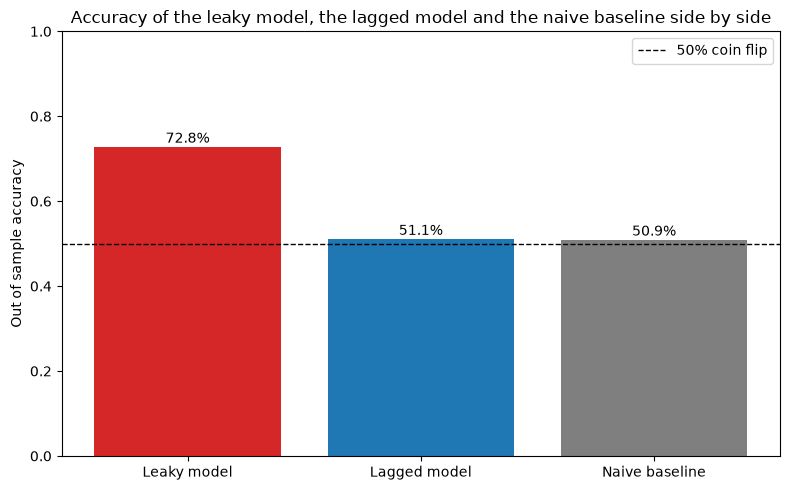

In [5]:
labels = ["Leaky model", "Lagged model", "Naive baseline"]
values = [leaky_acc, lagged_acc, baseline_acc]
colors = ["#d62728", "#1f77b4", "#7f7f7f"]

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, values, color=colors)
for bar, v in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f"{v:.1%}", ha="center")
plt.axhline(0.5, color="black", linestyle="--", linewidth=1, label="50% coin flip")
plt.ylim(0, 1)
plt.ylabel("Out of sample accuracy")
plt.legend()
plt.title("Accuracy of the leaky model, the lagged model and the naive baseline side by side")
plt.tight_layout()
plt.show()

## Step 5: Look at every window, not just the average
One average can hide a lot. Here is the honest model's accuracy in each 7-day test window. The shaded band shows how far a pure coin flip typically wanders in a window of 168 hours. If the dots mostly live inside that band, the model is doing what a coin does.

Lagged model per-window accuracy: min 0.429, max 0.637, std 0.040
Windows where lagged model beats baseline: 21 of 47
Windows above the coin flip noise band:    3 of 47


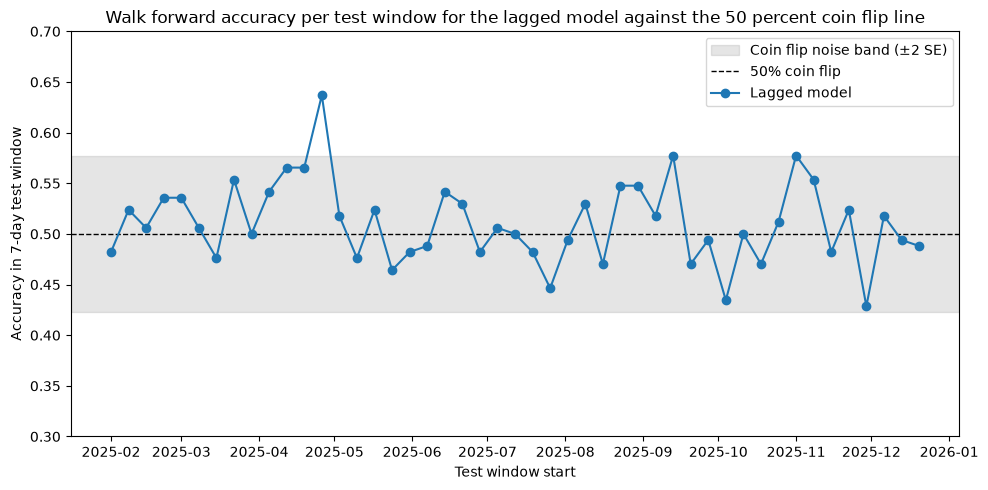

In [6]:
window_two_se = 2 * np.sqrt(0.25 / 168)
beats = (lagged_windows["model_acc"] > lagged_windows["baseline_acc"]).sum()

print(f"Lagged model per-window accuracy: min {lagged_windows.model_acc.min():.3f}, "
      f"max {lagged_windows.model_acc.max():.3f}, std {lagged_windows.model_acc.std():.3f}")
print(f"Windows where lagged model beats baseline: {beats} of {len(lagged_windows)}")
print(f"Windows above the coin flip noise band:    "
      f"{(lagged_windows.model_acc > 0.5 + window_two_se).sum()} of {len(lagged_windows)}")

plt.figure(figsize=(10, 5))
plt.axhspan(0.5 - window_two_se, 0.5 + window_two_se, color="grey", alpha=0.2,
            label="Coin flip noise band (±2 SE)")
plt.axhline(0.5, color="black", linestyle="--", linewidth=1, label="50% coin flip")
plt.plot(lagged_windows["test_start"], lagged_windows["model_acc"], marker="o",
         color="#1f77b4", label="Lagged model")
plt.ylim(0.3, 0.7)
plt.ylabel("Accuracy in 7-day test window")
plt.xlabel("Test window start")
plt.legend(loc="upper right")
plt.title("Walk forward accuracy per test window for the lagged model against the 50 percent coin flip line")
plt.tight_layout()
plt.show()

## Step 6: Turn the signal into a strategy and pay the fees
Accuracy is not money, so the last step trades it. The rule: hold Bitcoin for the next hour when the honest model says "up", sit in cash when it says "down". Every switch costs 0.1 percent for fees and slippage. I compare that with simply buying and holding over the same out of sample hours.

I also print what the leaky model would have "earned". It's not plotted because it cannot exist in real life, but that number is exactly the kind of screenshot that ends up in a whale alert thread.

Buy and hold return:            +15.4%
Inflow signal strategy return:  -79.9%  (2,313 position switches)
Leaky 'strategy' (impossible):  +1480513.4%  (3,842 position switches)


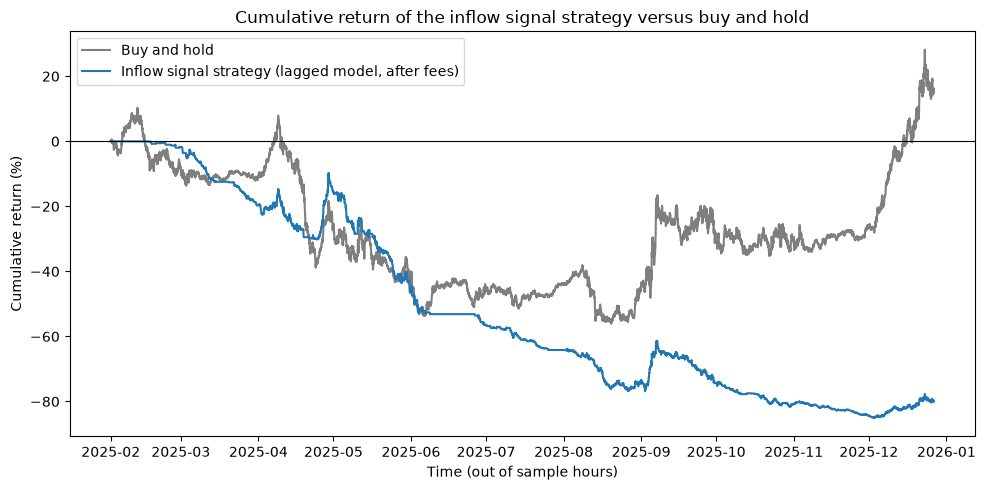

In [7]:
fee = 0.001
test_rets = data.loc[tested, "next_ret"]

def strategy_curve(prob):
    pos = (prob[tested] > 0.5).astype(float)
    switches = pos.diff().abs().fillna(pos.iloc[0])
    log_ret = pos * test_rets + np.log(1 - fee) * switches
    return np.exp(log_ret.cumsum()) - 1, int(switches.sum())

lagged_curve, lagged_trades = strategy_curve(lagged_prob)
leaky_curve, leaky_trades = strategy_curve(leaky_prob)
buy_hold_curve = np.exp(test_rets.cumsum()) - 1

print(f"Buy and hold return:            {buy_hold_curve.iloc[-1]:+.1%}")
print(f"Inflow signal strategy return:  {lagged_curve.iloc[-1]:+.1%}  ({lagged_trades:,} position switches)")
print(f"Leaky 'strategy' (impossible):  {leaky_curve.iloc[-1]:+.1%}  ({leaky_trades:,} position switches)")

plt.figure(figsize=(10, 5))
plt.plot(buy_hold_curve.index, buy_hold_curve * 100, color="#7f7f7f", label="Buy and hold")
plt.plot(lagged_curve.index, lagged_curve * 100, color="#1f77b4", label="Inflow signal strategy (lagged model, after fees)")
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Cumulative return (%)")
plt.xlabel("Time (out of sample hours)")
plt.legend()
plt.title("Cumulative return of the inflow signal strategy versus buy and hold")
plt.tight_layout()
plt.show()

## What this shows
The data was built so whales only react to price, and the honest pipeline found exactly that: the lagged model sits on the coin flip line window after window and fails the bar I wrote down in Step 0. The leaky model looked like a money printer because it was reading the answer off the back of the card.

The strategy chart is the practical lesson. A signal that switches position often and is right about half the time doesn't just fail to make money, it pays fees to lose it. That's a null result, and as the post says, it's a win: the filter did its job before a real agent touched real money.

To reuse this on your own data, swap Step 1 for real inflows and prices at the same frequency, keep Steps 2 to 6 as they are, and write your own Step 0 *first*.